# Market Dynamics & the Reversal Strategy

The 5-minute Up/Down market is an **at-the-money digital option** on a crypto diffusion:
the YES token's fair value is `P(S_{t+5m} > S_t | F_t)`, where `S` is the underlying
(BTC/ETH/…) price. This notebook characterises the markets as a **stochastic process**
and shows — with models, not just regressions — why no directional edge exists, then
re-examines the cross-window **reversal** strategy under audited methodology.

**Data.** Underlying = Binance 1-minute klines aligned to each window's exact timestamps
(6 assets; HYPE not on Binance). Binary = the executed trade tape (7 assets) + resolution.
**Token-path stats use a constructed mid** `(yes+(1−no))/2` to reduce bid/ask bounce
(Roll 1984); raw prints are a sensitivity check. Methodology audit:
`research/dynamics_design_spec.md`, `research/reversal_audit.md`.

In [1]:
import sys, os, logging, math
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
logging.basicConfig(level=logging.WARNING)
from polymarket_arb import (load_all, clustered_tstat, autocorr_table, sample_decay,
                            friction_grid, block_bootstrap)
from polymarket_arb.dynamics import (SPOT_ASSETS, all_spot_returns, moments, variance_ratio,
    digital_snr, load_spot, spot_resolution_agreement, token_mid_path, token_path,
    lag1_autocorr, crossing_count, resample_last, fraction_time_above, arcsine_cdf,
    opening_mid_prob, calibration_curve, brier_score, terminal_convergence,
    window_spot_features, yes_no_sum_stats, ljung_box, arch_lm)
from polymarket_arb.momentum import MomentumBacktester, MomentumConfig
pd.set_option("display.width", 140); plt.rcParams["figure.figsize"] = (9, 3.4)

data = load_all(count=500, cache_dir="../.cache")
allw = [w for ws in data.values() for w in ws]
rets = all_spot_returns(cache_dir="../data/spot")
spots = {a: load_spot(a, "../data/spot") for a in SPOT_ASSETS}
print(f"{len(allw)} windows / {len(data)} assets; spot for {sum(1 for a in spots if spots[a])} assets")

3500 windows / 7 assets; spot for 6 assets


## 1 — The underlying: a near-driftless, fat-tailed random walk

If the underlying is a random walk with ~zero 5-min drift, the digital sits at ~0.5 and
no direction is predictable. Below: return moments, the Lo-MacKinlay variance-ratio test
(heteroskedasticity-robust **z\***, since vol clusters), and Ljung-Box / ARCH diagnostics.

In [2]:
rows = []
for a, rs in rets.items():
    m = moments(rs); vr5 = variance_ratio(rs, 5)
    rows.append({"asset": a, "n": m["n"], "mean": m["mean"], "sd": m["std"],
                 "skew": round(m["skew"], 2), "exkurt": round(m["exkurt"], 1),
                 "VR5": round(vr5["vr"], 3), "z*5": round(vr5["z_star"], 2),
                 "LB(r) p": round(ljung_box(rs, 10)["lb_pvalue"], 3),
                 "LB(r^2) p": round(ljung_box([r*r for r in rs], 10)["lb_pvalue"], 3),
                 "ARCH p": round(arch_lm(rs, 10)["lm_pvalue"], 3)})
display(pd.DataFrame(rows).set_index("asset"))

,n,mean,sd,skew,exkurt,VR5,z*5,LB(r) p,LB(r^2) p,ARCH p
asset,,,,,,,,,,
btc,5445,-0.000004,0.000497,0.41,9.4,1.034,0.64,0.000,0.0,0.0
eth,5435,-0.000005,0.000639,0.18,11.8,1.009,0.16,0.003,0.0,0.0
sol,5440,0.000001,0.000838,0.06,7.3,1.043,0.91,0.042,0.0,0.0
bnb,5450,-0.000006,0.000514,-0.80,12.9,0.979,-0.40,0.040,0.0,0.0
doge,4330,-0.000010,0.000689,-0.26,12.8,0.984,-0.28,0.006,0.0,0.0
xrp,4325,-0.000013,0.000720,0.15,8.0,0.951,-0.89,0.114,0.0,0.0


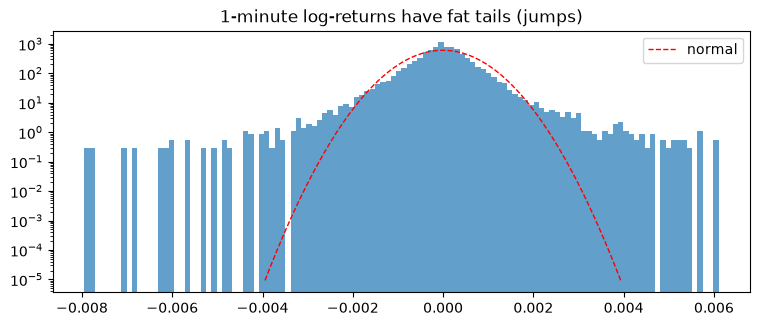

In [3]:
# fat tails: pooled 1m log-returns vs a fitted normal (log-scale)
pooled = [r for rs in rets.values() for r in rs]
mu = np.mean(pooled); sd = np.std(pooled)
plt.hist(pooled, bins=120, density=True, alpha=.7, color="tab:blue")
xs = np.linspace(mu-6*sd, mu+6*sd, 300)
plt.plot(xs, np.exp(-(xs-mu)**2/(2*sd**2))/(sd*np.sqrt(2*np.pi)), "r--", lw=1, label="normal")
plt.yscale("log"); plt.legend(); plt.title("1-minute log-returns have fat tails (jumps)"); plt.show()

## 2 — Why no directional edge can exist (the digital-option argument)

Fair YES = `Φ(SNR)`, `SNR = μ·√n / σ`. With `μ, σ` measured from the data, the per-asset
SNR is ~0.02 in magnitude (≈0), so `P(Up) ≈ 0.5` to first order. **Volatility sets the *level*
(it pins the price near 0.5); it cannot create a directional edge.** Model vs realized:

In [4]:
rows = []
for a, ws in data.items():
    if a not in rets: continue
    m = moments(rets[a])
    rows.append({"asset": a, "SNR": round(digital_snr(m["mean"], m["std"], 5)["snr"], 4),
                 "model fair P(Up)": round(digital_snr(m["mean"], m["std"], 5)["fair_up"], 4),
                 "realized P(Up)": round(np.mean([w.resolution_yes for w in ws]), 4), "n": len(ws)})
display(pd.DataFrame(rows).set_index("asset"))

,SNR,model fair P(Up),realized P(Up),n
asset,,,,
btc,-0.0169,0.4933,0.534,500
eth,-0.0163,0.4935,0.494,500
sol,0.0029,0.5011,0.516,500
bnb,-0.0265,0.4894,0.508,500
doge,-0.0310,0.4876,0.494,500
xrp,-0.0392,0.4844,0.492,500


## 3 — Data validation: spot direction vs Polymarket resolution

In [5]:
ag = spot_resolution_agreement(allw, cache_dir="../data/spot")
display(pd.DataFrame(ag).T)
print("pooled agreement:",
      round(sum(d['agree_rate']*d['n'] for d in ag.values())/sum(d['n'] for d in ag.values()), 4))

,n,agree_rate
btc,337.0,0.952522
eth,495.0,0.981818
sol,479.0,0.987474
bnb,493.0,0.979716
doge,477.0,0.991614
xrp,481.0,0.979210


pooled agreement: 0.9801


## 4 — The binary is well-calibrated (with a wide effective spread)

Calibration (opening mid vs realized YES frequency, Wilson CIs + Brier), the opening mid
≈ 0.5 (cluster-robust), whether vol predicts direction, and the **effective spread**
(YES+NO print sum vs 1 = the round-trip overround that swamps thin edges).

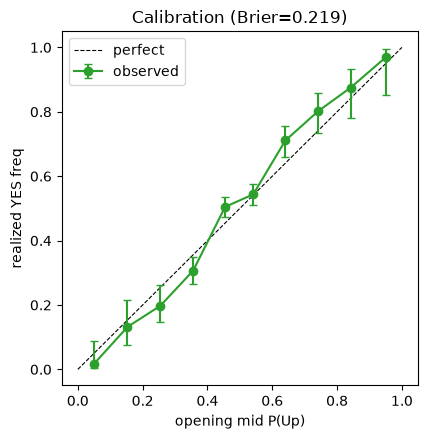

opening mid mean dev from 0.5: -0.0146, cluster-robust t=-3.63 (889 clusters)
|opening-0.5| ~ realized vol: slope=12.42, corr=0.096 (weak +ve magnitude link; vol sets distance from 0.5, NOT the sign; descriptive/contemporaneous)


no-arb: mean (YES+NO) print sum = 1.090


In [6]:
opens, calib, volpairs = [], [], []
for w in allw:
    op = opening_mid_prob(w)
    if op is None: continue
    opens.append((w.open_ts, op)); calib.append((op, 1.0 if w.resolution_yes == 1.0 else 0.0))
    a = w.asset.lower()
    if spots.get(a):
        ft = window_spot_features(w, spots[a])
        if ft: volpairs.append((ft["rvol"], abs(op-0.5)))
cc = calibration_curve(calib, 10)
plt.figure(figsize=(4.6, 4.6)); plt.plot([0,1],[0,1],"k--",lw=.8,label="perfect")
plt.errorbar([c["mean_pred"] for c in cc],[c["freq"] for c in cc],
    yerr=[[c["freq"]-c["lo"] for c in cc],[c["hi"]-c["freq"] for c in cc]],
    fmt="o-", color="tab:green", capsize=3, label="observed")
plt.xlabel("opening mid P(Up)"); plt.ylabel("realized YES freq")
plt.title(f"Calibration (Brier={brier_score(calib):.3f})"); plt.legend(); plt.show()

dev = clustered_tstat([o-0.5 for _, o in opens], [t for t, _ in opens])
print(f"opening mid mean dev from 0.5: {dev['mean']:+.4f}, cluster-robust t={dev['t']:.2f} "
      f"({dev['n_clusters']} clusters)")
vx = np.array([x for x, _ in volpairs]); vy = np.array([y for _, y in volpairs])
slope = np.polyfit(vx, vy, 1)[0]; corr = np.corrcoef(vx, vy)[0, 1]
print(f"|opening-0.5| ~ realized vol: slope={slope:.2f}, corr={corr:.3f} "
      f"(weak +ve magnitude link; vol sets distance from 0.5, NOT the sign; descriptive/contemporaneous)")
sums = [s["mean_sum"] for s in (yes_no_sum_stats(w) for w in allw) if s]
print(f"no-arb: mean (YES+NO) print sum = {np.mean(sums):.3f}")

## 5 — The token mid is a bounded martingale; "reverses early" is arcsine-like

The mid must converge to the realized outcome by close (bounded martingale). Its increments
have ~zero autocorrelation **on the constructed mid** — the negative value on raw prints is
**bid/ask bounce**, not predictable alpha. The frequent early 0.5-crossings are the
arcsine/sign-change behaviour of a martingale near 0.5 (the overlay is an approximation —
level fixed at 0.5, and the token is a bounded/absorbing martingale, not free BM) — no
serial structure to trade.

increment lag-1 autocorr: mid=+0.042  raw=-0.139 (raw negative = bid/ask bounce)
0.5-crossings/window (both on 10s grid): mid=1.5  raw=1.5


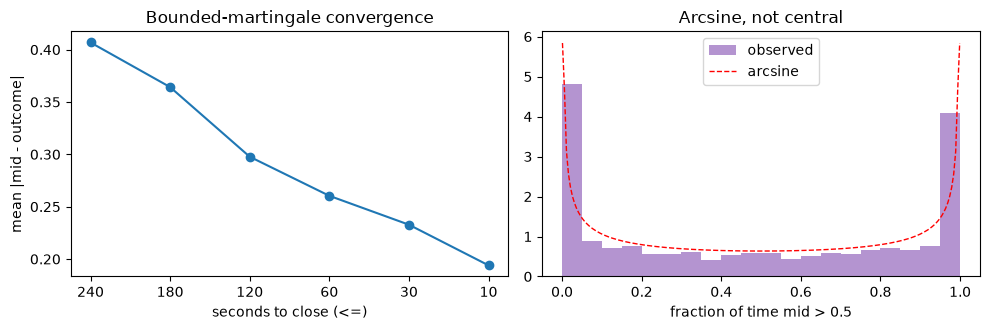

In [7]:
mid_ac, raw_ac, cross_raw, cross_mid, frac = [], [], [], [], []
for w in allw:
    mp, rp = token_mid_path(w), token_path(w)
    if len(mp) >= 5:
        mids = [p for _, p in mp]; mi = np.diff(mids)
        ac = lag1_autocorr(list(mi));  mid_ac.append(ac) if ac == ac else None
        cross_mid.append(crossing_count(resample_last(mp, w.open_ts, w.close_ts, 10.0)))
        fa = fraction_time_above(mp);  frac.append(fa) if fa == fa else None
    if len(rp) >= 5:
        ac = lag1_autocorr(list(np.diff([p for _, p in rp])));  raw_ac.append(ac) if ac == ac else None
        cross_raw.append(crossing_count(resample_last(rp, w.open_ts, w.close_ts, 10.0)))  # same grid as mid
print(f"increment lag-1 autocorr: mid={np.mean(mid_ac):+.3f}  raw={np.mean(raw_ac):+.3f} (raw negative = bid/ask bounce)")
print(f"0.5-crossings/window (both on 10s grid): mid={np.mean(cross_mid):.1f}  raw={np.mean(cross_raw):.1f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
term = [t for t in terminal_convergence(allw) if t["n"] > 0][::-1]
ax[0].plot([str(t["sec_to_close<="]) for t in term], [t["mean_abs_err"] for t in term], "o-")
ax[0].set_xlabel("seconds to close (<=)"); ax[0].set_ylabel("mean |mid - outcome|")
ax[0].set_title("Bounded-martingale convergence")
ax[1].hist(frac, bins=20, density=True, alpha=.7, color="tab:purple", label="observed")
gx = np.linspace(.001, .999, 200)
ax[1].plot(gx, np.gradient([arcsine_cdf(x) for x in gx], gx), "r--", lw=1, label="arcsine")
ax[1].set_xlabel("fraction of time mid > 0.5"); ax[1].legend(); ax[1].set_title("Arcsine, not central")
plt.tight_layout(); plt.show()

## 6 — The cross-window reversal strategy (audited)

Given an efficient near-martingale, betting against the previous window should not pay.
The audit (`research/reversal_audit.md`) confirmed the autocorrelation is genuine but weak,
and the tradeable edge vanishes under realistic ask entry + cluster-robust SEs.

In [8]:
display(pd.DataFrame(autocorr_table(data)).set_index("asset").round(3))
display(pd.DataFrame(sample_decay(data)).round(3))

,n_pairs,lag1_autocorr,z,base_up_rate,p_up_after_up,p_up_after_down,repeat_rate
asset,,,,,,,
btc,497,0.026,0.571,0.535,0.547,0.522,0.515
eth,495,0.034,0.759,0.491,0.508,0.474,0.517
sol,496,0.027,0.609,0.514,0.527,0.500,0.514
bnb,494,0.044,0.985,0.510,0.532,0.488,0.522
doge,495,-0.055,-1.217,0.495,0.467,0.522,0.473
xrp,493,0.014,0.312,0.495,0.502,0.488,0.507
hype,492,0.014,0.300,0.472,0.479,0.465,0.508
ALL,3462,0.016,0.951,0.502,0.510,0.494,0.508


,label,n_pairs,lag1_autocorr,z
0,recent 250 x 5 orig assets,1233,0.014,0.481
1,recent 500 x 5 orig assets,2477,0.016,0.809
2,ALL 7 assets (full depth),3462,0.016,0.951


In [9]:
rev = pd.DataFrame(friction_grid(allw, "reversal"))
display(rev.round(4))
res0 = MomentumBacktester(MomentumConfig(direction="reversal")).run(allw)
boot = block_bootstrap([r.pnl for r in res0], [r.start_ts for r in res0])
print(f"headline reversal (0 spread/0 fee): mean/bet {boot['mean']:+.4f}, "
      f"95% CI [{boot['lo']:.4f}, {boot['hi']:.4f}], P(<=0)={boot['p_le_0']:.2f}")

,half_spread,fee_bps,n,win_rate,avg_entry,avg_pnl,t_naive,t_clustered,n_clusters
0,0.000,0,3342,0.5051,0.5252,-0.0202,-2.4479,-1.7264,881
1,0.000,100,3342,0.5051,0.5252,-0.0242,-2.9334,-2.0686,881
2,0.000,200,3342,0.5051,0.5252,-0.0282,-3.4189,-2.4107,881
3,0.010,0,3342,0.5051,0.5352,-0.0302,-3.6622,-2.5827,881
4,0.010,100,3342,0.5051,0.5352,-0.0341,-4.1439,-2.9222,881
5,0.010,200,3342,0.5051,0.5352,-0.0381,-4.6256,-3.2615,881
6,0.015,0,3342,0.5051,0.5402,-0.0351,-4.2680,-3.0099,881
7,0.015,100,3342,0.5051,0.5402,-0.0391,-4.7473,-3.3476,881
8,0.015,200,3342,0.5051,0.5402,-0.0430,-5.2266,-3.6851,881
9,0.020,0,3342,0.5051,0.5452,-0.0401,-4.8732,-3.4366,881


headline reversal (0 spread/0 fee): mean/bet -0.0198, 95% CI [-0.0427, 0.0023], P(<=0)=0.96


## Verdict

The 5-min Up/Down market is an **efficiently-priced at-the-money digital option on a
near-driftless, fat-tailed random walk**: well-calibrated (low Brier), its mid a bounded
martingale converging to the outcome, the underlying a 5-min random walk (VR≈1, z\*
insignificant), directional SNR ≈ 0.02 (≈0). This is the **mechanism** behind every empirical
null (arb in the companion notebook; momentum & reversal here). The "reverses many times
early" intuition is the arcsine behaviour of a martingale near 0.5 — real, but with no
serial structure to trade. The only remaining lever is execution/microstructure, which the
forward order-book collector is gathering data to test.